Premier League 2026/2027 First Third Passing Activity

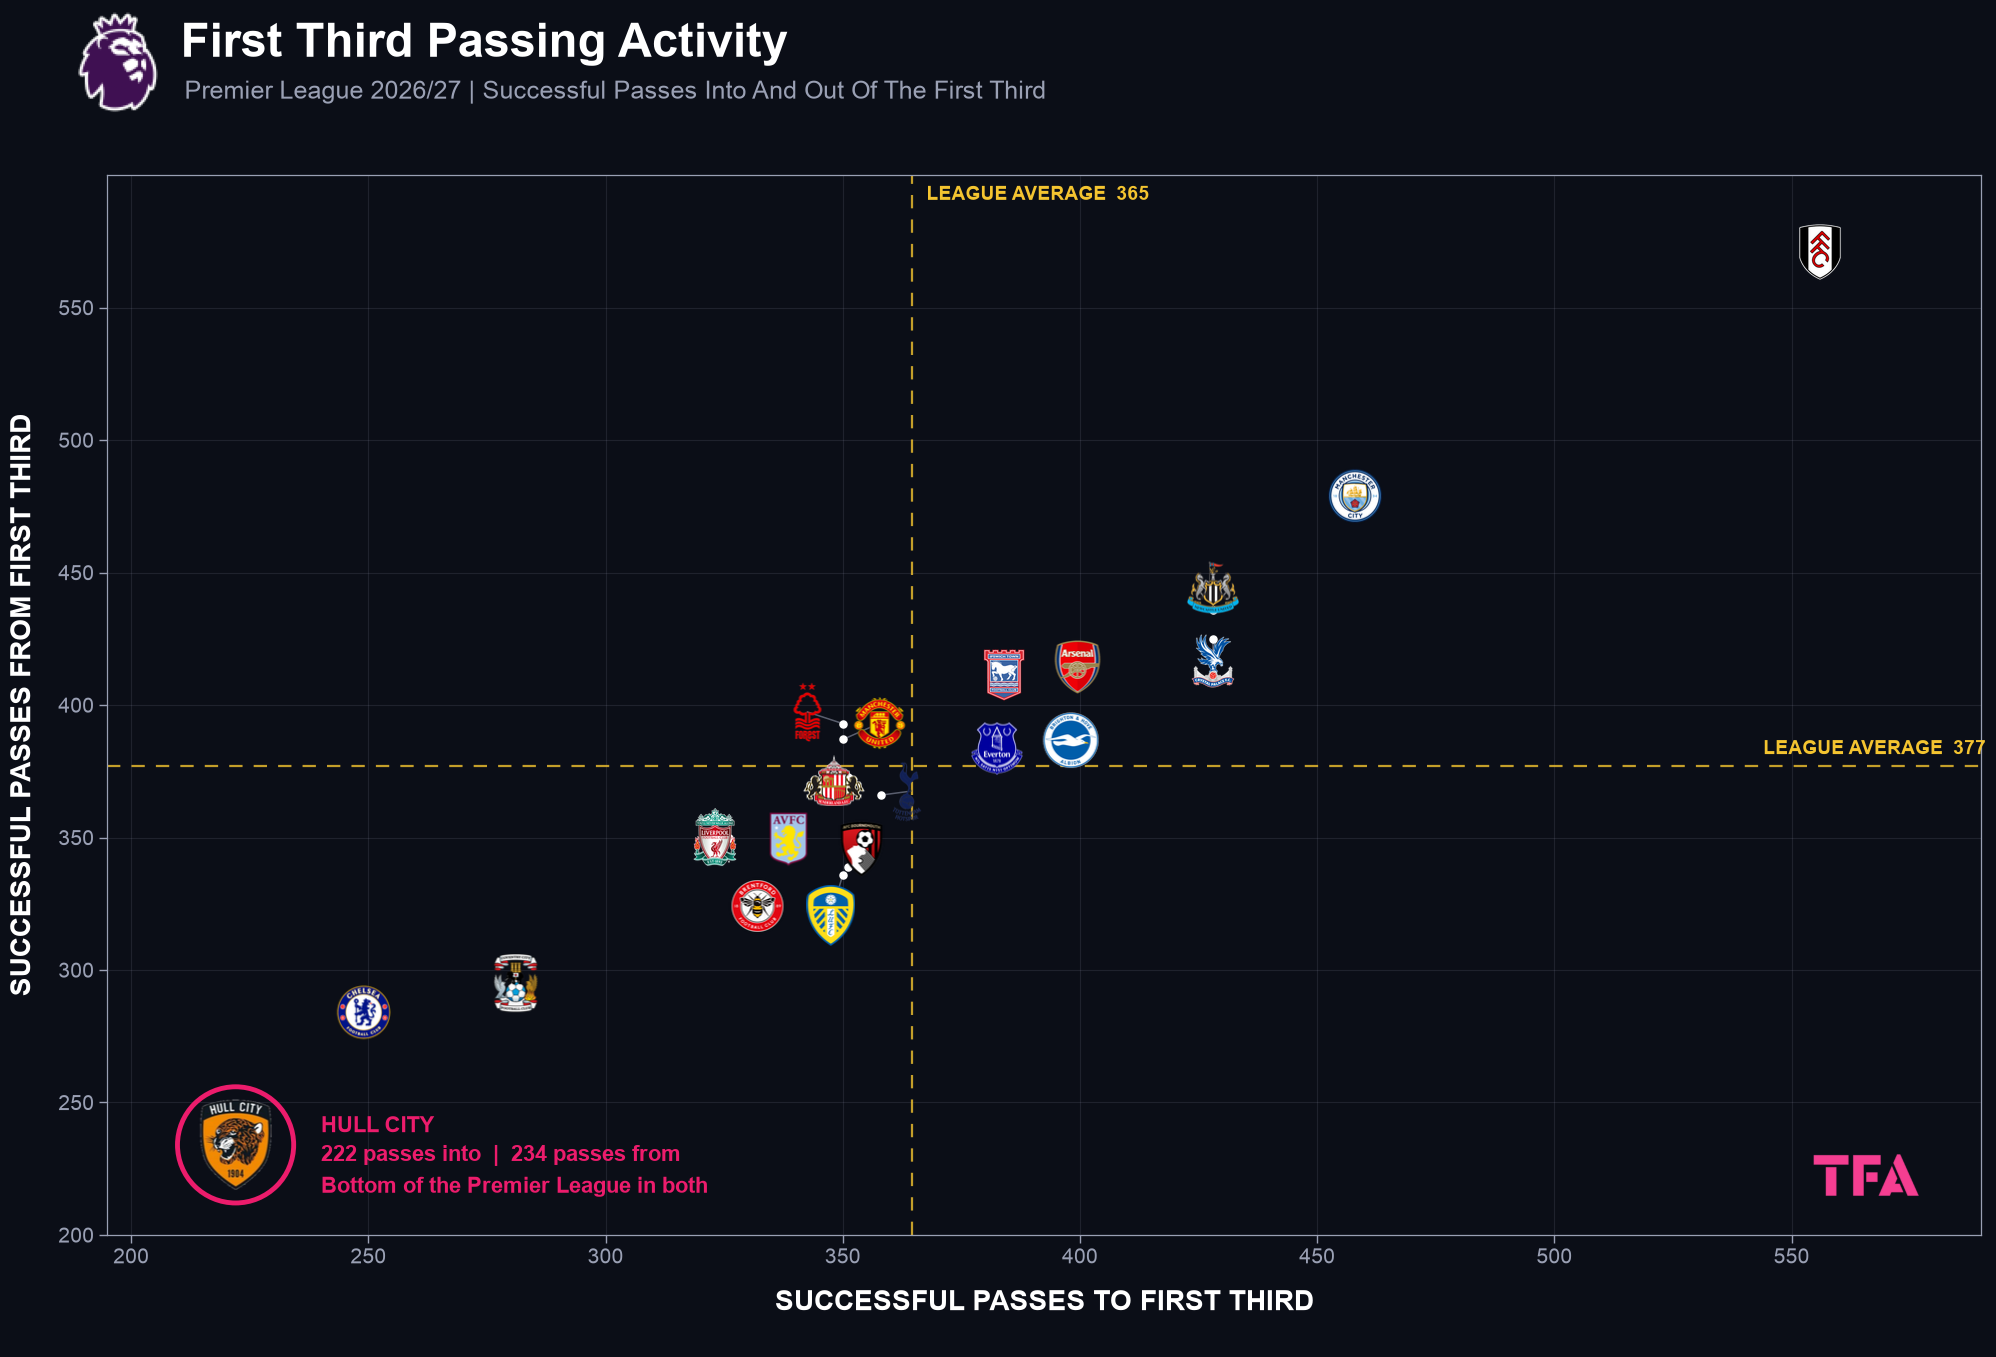

In [96]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

NAMES = {
    "Fulham": "Fulham",
    "Manchester City": "Manchester City",
    "Crystal Palace": "Crystal Palace",
    "Newcastle United": "Newcastle United",
    "Arsenal FC": "Arsenal",
    "Brighton and Hove Albion": "Brighton",
    "Ipswich Town": "Ipswich Town",
    "Everton FC": "Everton",
    "Tottenham Hotspur": "Tottenham Hotspur",
    "AFC Sunderland": "Sunderland",
    "AFC Bournemouth": "Bournemouth",
    "Manchester United": "Manchester United",
    "Nottingham Forrest": "Nottingham Forest",
    "Leeds United": "Leeds United",
    "Aston Villa": "Aston Villa",
    "Brentford": "Brentford",
    "Liverpool FC": "Liverpool",
    "Coventry City": "Coventry City",
    "Chelsea": "Chelsea",
    "Hull City": "Hull City",
}

INTO = {
    "Fulham": 556, "Manchester City": 458, "Crystal Palace": 428, "Newcastle United": 428,
    "Arsenal FC": 399, "Brighton and Hove Albion": 398, "Ipswich Town": 384, "Everton FC": 383,
    "Tottenham Hotspur": 358, "AFC Sunderland": 351, "AFC Bournemouth": 351, "Manchester United": 350,
    "Nottingham Forrest": 350, "Leeds United": 350, "Aston Villa": 336, "Brentford": 335,
    "Liverpool FC": 326, "Coventry City": 281, "Chelsea": 249, "Hull City": 222,
}

FROM = {
    "Fulham": 571, "Manchester City": 479, "Newcastle United": 436, "Crystal Palace": 425,
    "Ipswich Town": 409, "Arsenal FC": 408, "Nottingham Forrest": 393, "Brighton and Hove Albion": 393,
    "Manchester United": 387, "Everton FC": 386, "AFC Sunderland": 373, "Tottenham Hotspur": 366,
    "Liverpool FC": 350, "Aston Villa": 345, "AFC Bournemouth": 339, "Leeds United": 336,
    "Brentford": 330, "Coventry City": 295, "Chelsea": 284, "Hull City": 234,
}

teams = list(INTO.keys())
xs = np.array([INTO[t] for t in teams], dtype=float)
ys = np.array([FROM[t] for t in teams], dtype=float)
avg_x = xs.mean()
avg_y = ys.mean()

DPI = 100
W, H = 2048, 1536
LOGO_PX = 62
HULL_PX = 92

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes([0.065, 0.085, 0.915, 0.69])
ax.set_xlim(195, 590)
ax.set_ylim(205, 600)
ax.set_xticks(range(200, 600, 50))
ax.set_yticks(range(200, 600, 50))
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, color="#9AA0B4", alpha=0.14, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("SUCCESSFUL PASSES TO FIRST THIRD", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)
ax.set_ylabel("SUCCESSFUL PASSES FROM FIRST THIRD", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

ax.axvline(avg_x, color="#F4C430", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.8, zorder=1)
ax.axhline(avg_y, color="#F4C430", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.8, zorder=1)
ax.text(avg_x + 3, 596, f"LEAGUE AVERAGE  {avg_x:.0f}", color="#F4C430", fontsize=14, fontweight="bold", va="top", ha="left")
ax.text(591, avg_y + 3, f"LEAGUE AVERAGE  {avg_y:.0f}", color="#F4C430", fontsize=14, fontweight="bold", va="bottom", ha="right")

ax.scatter(xs, ys, s=26, color="#FFFFFF", zorder=3)

pts = ax.transData.transform(np.column_stack([xs, ys]))
pos = pts.copy()
bbox = ax.get_window_extent()
min_d = 74
pad = 48

for _ in range(800):
    moved = False
    for i in range(len(teams)):
        for j in range(i + 1, len(teams)):
            d = pos[j] - pos[i]
            dist = np.hypot(d[0], d[1])
            if dist < min_d:
                if dist < 1e-6:
                    d = np.array([1.0, 0.5])
                    dist = np.hypot(d[0], d[1])
                vec = d / dist * (min_d - dist) / 2
                pos[i] -= vec
                pos[j] += vec
                moved = True
    pos += (pts - pos) * 0.015
    pos[:, 0] = np.clip(pos[:, 0], bbox.x0 + pad, bbox.x1 - pad)
    pos[:, 1] = np.clip(pos[:, 1], bbox.y0 + pad, bbox.y1 - pad)
    if not moved:
        break

logo_data = ax.transData.inverted().transform(pos)

hull_idx = teams.index("Hull City")
ax.scatter([xs[hull_idx]], [ys[hull_idx]], s=7000, facecolor="none", edgecolor="#EC1C6C", linewidth=3.5, zorder=4)

for i, raw in enumerate(teams):
    display = NAMES[raw]
    shift = np.hypot(*(pos[i] - pts[i]))
    if shift > 14:
        ax.plot([xs[i], logo_data[i][0]], [ys[i], logo_data[i][1]], color="#9AA0B4", alpha=0.55, linewidth=1.1, zorder=2)
    path = find_logo(display)
    if path:
        size = HULL_PX if raw == "Hull City" else LOGO_PX
        img = load_resized(path, size)
        box = OffsetImage(img, zoom=72 / DPI)
        ab = AnnotationBbox(box, (logo_data[i][0], logo_data[i][1]), frameon=False, box_alignment=(0.5, 0.5), zorder=5)
        ax.add_artist(ab)
    else:
        ax.text(logo_data[i][0], logo_data[i][1], display, color="#FFFFFF", fontsize=11, ha="center", va="center", zorder=5)

ax.text(
    xs[hull_idx] + 18, ys[hull_idx] - 4,
    f"HULL CITY\n{INTO['Hull City']} passes into  |  {FROM['Hull City']} passes from\nBottom of the Premier League in both",
    color="#EC1C6C", fontsize=16, fontweight="bold", va="center", ha="left", linespacing=1.5, zorder=6,
)

fig.text(0.249, 0.86, "First Third Passing Activity", color="#FFFFFF", fontsize=34, fontweight="bold", ha="center", va="center")
fig.text(0.313, 0.829, "Premier League 2026/27 | Successful Passes Into And Out Of The First Third", color="#9AA0B4", fontsize=18, ha="center", va="center")

ax_tfa = fig.add_axes([0.89, 0.079, 0.09, 0.09])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.027, 0.814, 0.069, 0.069])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Premier League 2026/27 | Offensive Touches In Phase Of Ball Possession

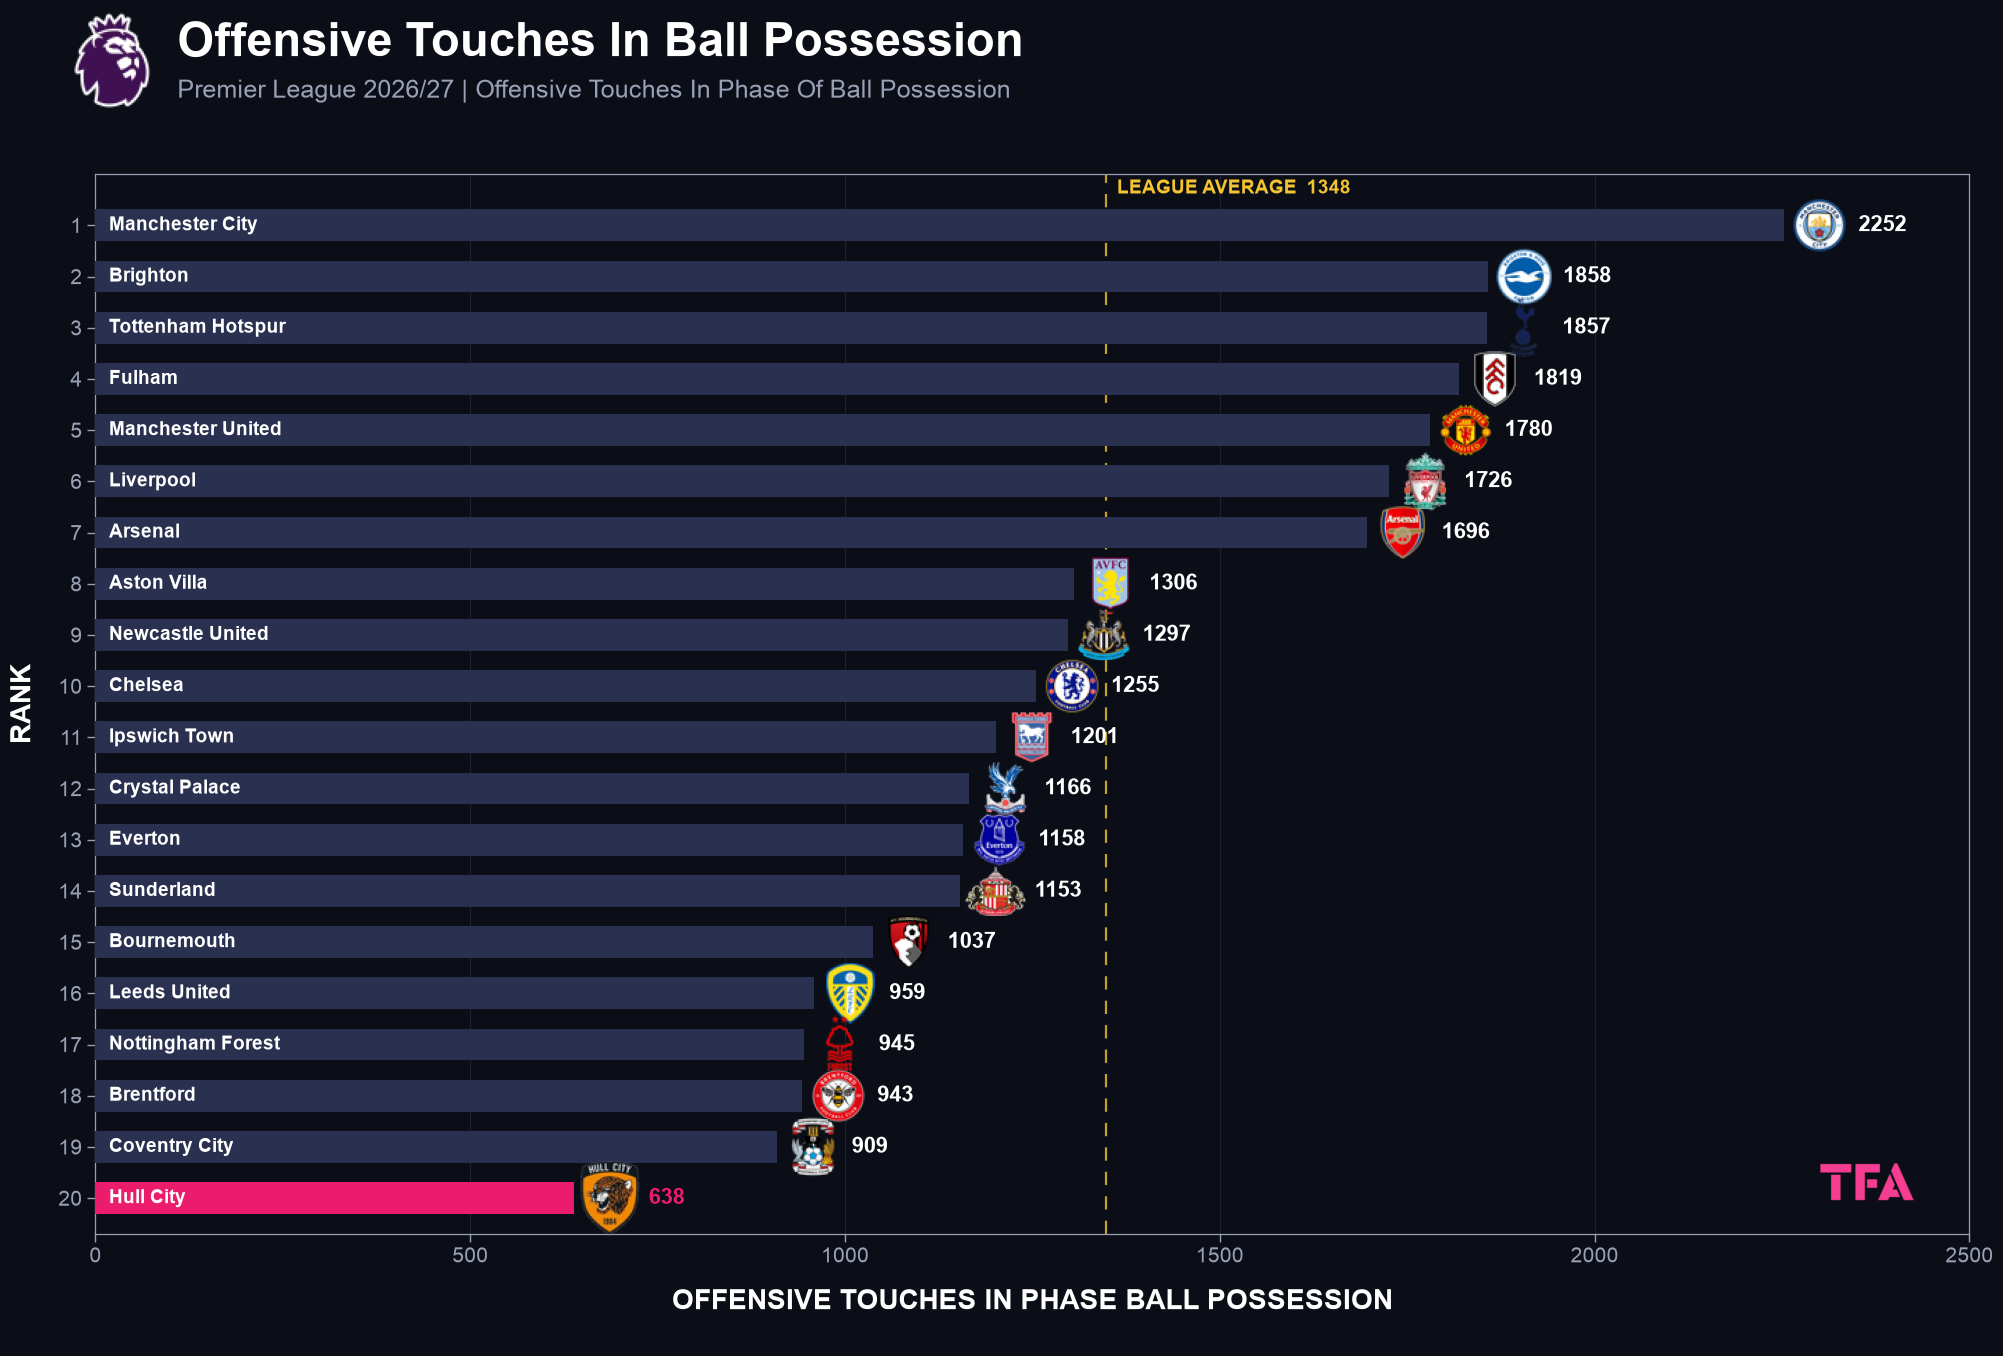

In [111]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

NAMES = {
    "Manchester City": "Manchester City",
    "Brighton and Hove Albion": "Brighton",
    "Tottenham Hotspur": "Tottenham Hotspur",
    "Fulham": "Fulham",
    "Manchester United": "Manchester United",
    "Liverpool FC": "Liverpool",
    "Arsenal FC": "Arsenal",
    "Aston Villa": "Aston Villa",
    "Newcastle United": "Newcastle United",
    "Chelsea": "Chelsea",
    "Ipswich Town": "Ipswich Town",
    "Crystal Palace": "Crystal Palace",
    "Everton FC": "Everton",
    "AFC Sunderland": "Sunderland",
    "AFC Bournemouth": "Bournemouth",
    "Leeds United": "Leeds United",
    "Nottingham Forrest": "Nottingham Forest",
    "Brentford": "Brentford",
    "Coventry City": "Coventry City",
    "Hull City": "Hull City",
}

TOUCHES = [
    ("Manchester City", 2252), ("Brighton and Hove Albion", 1858), ("Tottenham Hotspur", 1857),
    ("Fulham", 1819), ("Manchester United", 1780), ("Liverpool FC", 1726),
    ("Arsenal FC", 1696), ("Aston Villa", 1306), ("Newcastle United", 1297),
    ("Chelsea", 1255), ("Ipswich Town", 1201), ("Crystal Palace", 1166),
    ("Everton FC", 1158), ("AFC Sunderland", 1153), ("AFC Bournemouth", 1037),
    ("Leeds United", 959), ("Nottingham Forrest", 945), ("Brentford", 943),
    ("Coventry City", 909), ("Hull City", 638),
]

teams = [t for t, _ in TOUCHES]
values = np.array([v for _, v in TOUCHES], dtype=float)
ypos = np.arange(len(teams))
avg_v = values.mean()

DPI = 100
W, H = 2048, 1536
LOGO_PX = 44
HULL_PX = 54

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes([0.065, 0.085, 0.915, 0.69])
ax.set_xlim(0, 2500)
ax.set_ylim(19.7, -1.0)
ax.set_xticks(range(0, 2501, 500))
ax.set_yticks(ypos)
ax.set_yticklabels([str(i + 1) for i in ypos])
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, axis="x", color="#9AA0B4", alpha=0.14, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("OFFENSIVE TOUCHES IN PHASE BALL POSSESSION", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)
ax.set_ylabel("RANK", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

colors = ["#EC1C6C" if t == "Hull City" else "#2A3150" for t in teams]
ax.barh(ypos, values, height=0.62, color=colors, zorder=3)

ax.axvline(avg_v, color="#F4C430", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.8, zorder=2)
ax.text(avg_v + 15, -0.72, f"LEAGUE AVERAGE  {avg_v:.0f}", color="#F4C430", fontsize=14, fontweight="bold", va="center", ha="left")

for i, raw in enumerate(teams):
    display = NAMES[raw]
    is_hull = raw == "Hull City"
    ax.text(18, i, display, color="#FFFFFF", fontsize=14, fontweight="bold", va="center", ha="left", zorder=4)
    path = find_logo(display)
    if path:
        img = load_resized(path, HULL_PX if is_hull else LOGO_PX)
        box = OffsetImage(img, zoom=1)
        ab = AnnotationBbox(box, (values[i] + 48, i), frameon=False, box_alignment=(0.5, 0.5), zorder=5)
        ax.add_artist(ab)
    ax.text(values[i] + 100, i, f"{int(values[i])}", color="#EC1C6C" if is_hull else "#FFFFFF", fontsize=16, fontweight="bold", va="center", ha="left", zorder=5)

hull_idx = teams.index("Hull City")
ax.text(
    values[hull_idx] + 260, hull_idx - 0.6,
    f" ",
    color="#EC1C6C", fontsize=16, fontweight="bold", va="center", ha="left", linespacing=1.5, zorder=6,
)

fig.text(0.105, 0.86, "Offensive Touches In Ball Possession", color="#FFFFFF", fontsize=34, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.829, "Premier League 2026/27 | Offensive Touches In Phase Of Ball Possession", color="#9AA0B4", fontsize=18, ha="left", va="center")

ax_tfa = fig.add_axes([0.9, 0.079, 0.08, 0.08])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.0319, 0.816, 0.066, 0.066])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Premier League 2026/2027 Offensive Actions From And In The First Third

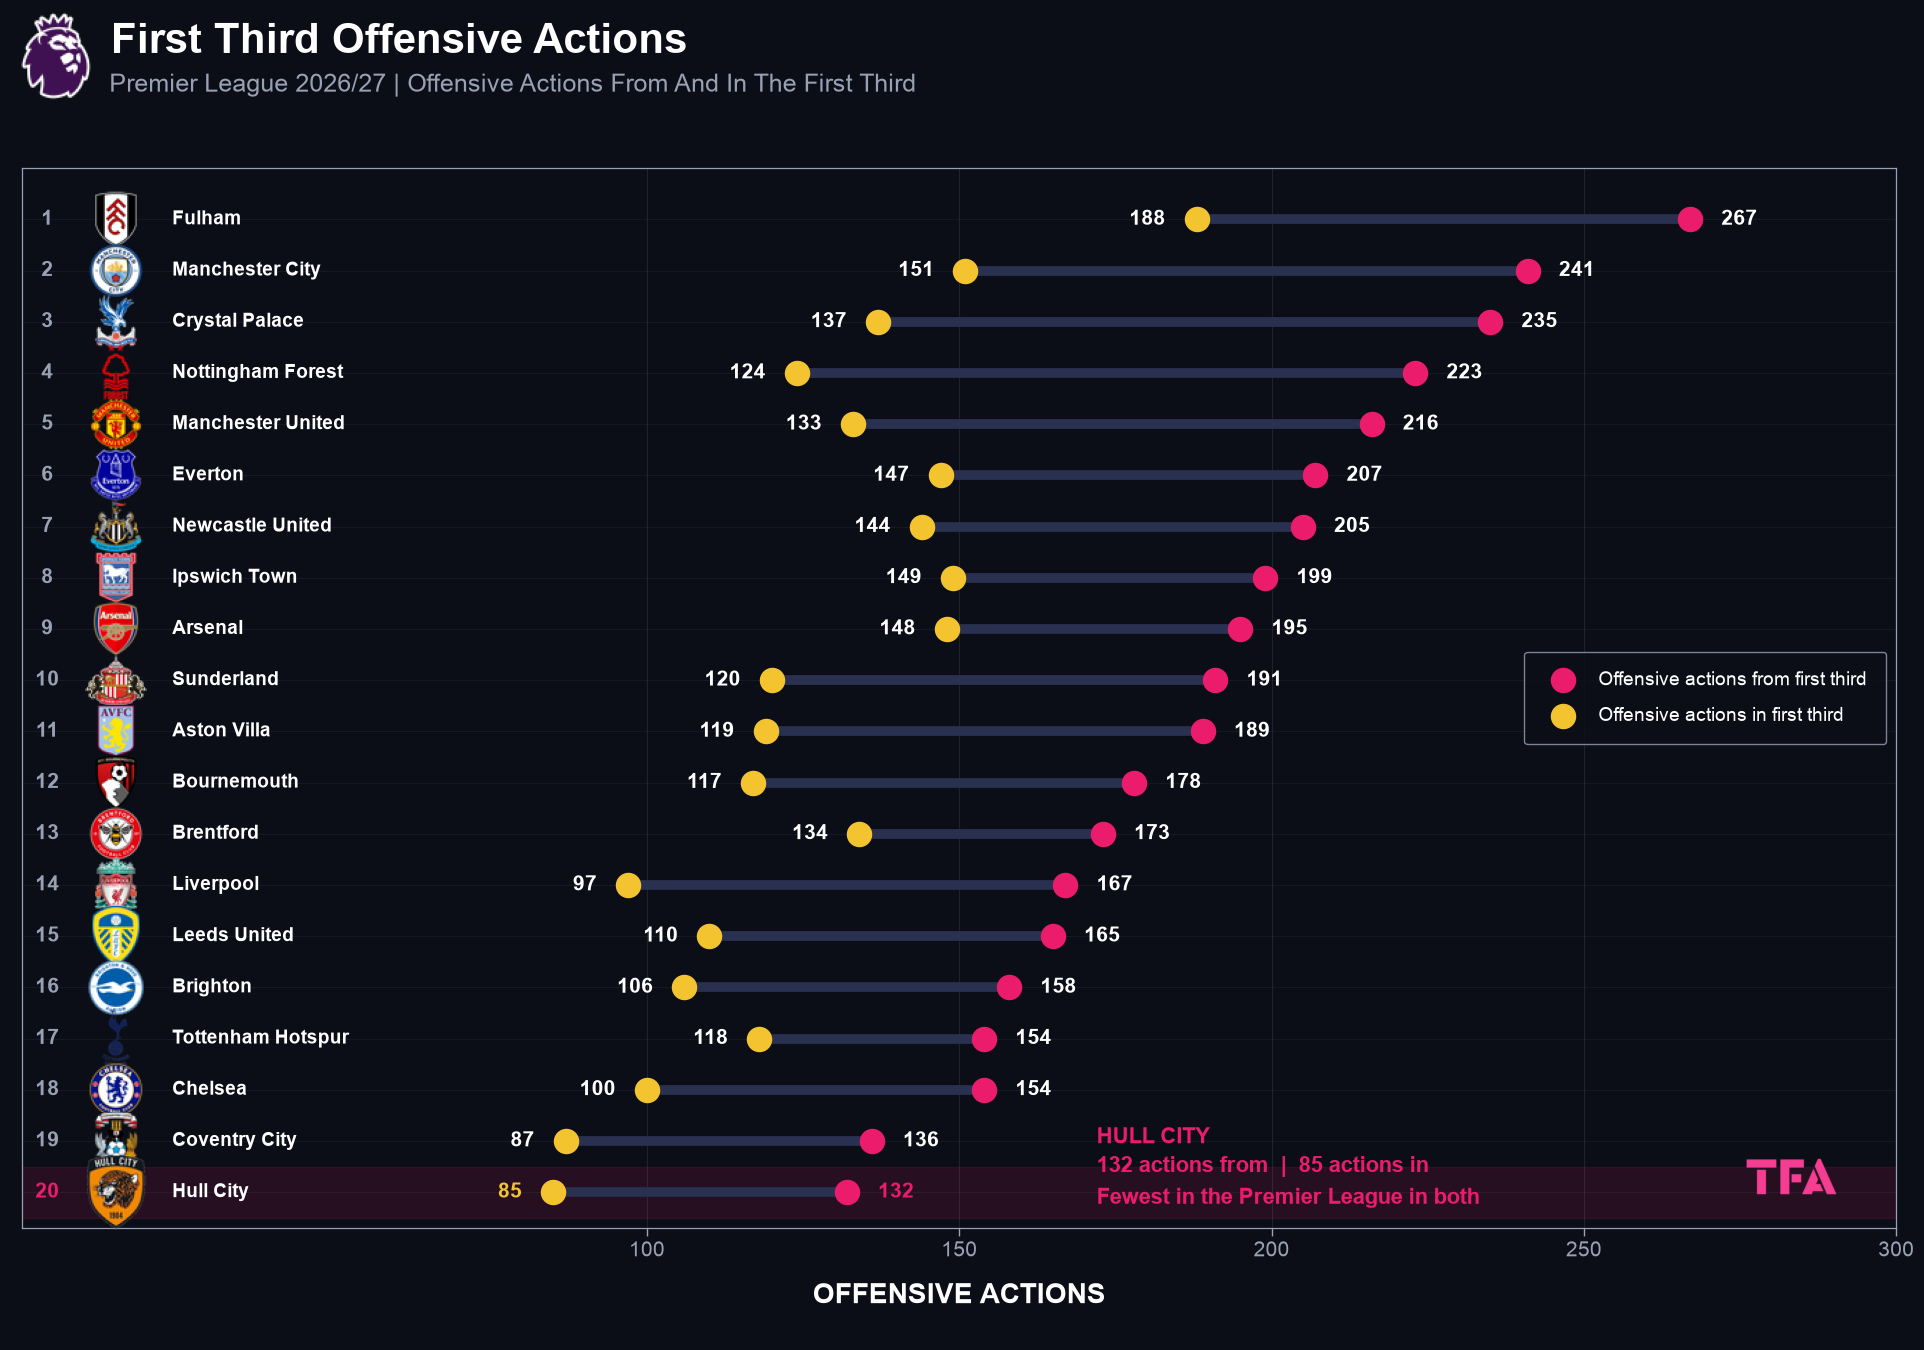

In [133]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

NAMES = {
    "Fulham": "Fulham",
    "Manchester City": "Manchester City",
    "Crystal Palace": "Crystal Palace",
    "Newcastle United": "Newcastle United",
    "Arsenal FC": "Arsenal",
    "Brighton and Hove Albion": "Brighton",
    "Ipswich Town": "Ipswich Town",
    "Everton FC": "Everton",
    "Tottenham Hotspur": "Tottenham Hotspur",
    "AFC Sunderland": "Sunderland",
    "AFC Bournemouth": "Bournemouth",
    "Manchester United": "Manchester United",
    "Nottingham Forrest": "Nottingham Forest",
    "Leeds United": "Leeds United",
    "Aston Villa": "Aston Villa",
    "Brentford": "Brentford",
    "Liverpool FC": "Liverpool",
    "Coventry City": "Coventry City",
    "Chelsea": "Chelsea",
    "Hull City": "Hull City",
}

FROM = [
    ("Fulham", 267), ("Manchester City", 241), ("Crystal Palace", 235), ("Nottingham Forrest", 223),
    ("Manchester United", 216), ("Everton FC", 207), ("Newcastle United", 205), ("Ipswich Town", 199),
    ("Arsenal FC", 195), ("AFC Sunderland", 191), ("Aston Villa", 189), ("AFC Bournemouth", 178),
    ("Brentford", 173), ("Liverpool FC", 167), ("Leeds United", 165), ("Brighton and Hove Albion", 158),
    ("Tottenham Hotspur", 154), ("Chelsea", 154), ("Coventry City", 136), ("Hull City", 132),
]

IN = {
    "Fulham": 188, "Manchester City": 151, "Ipswich Town": 149, "Arsenal FC": 148,
    "Everton FC": 147, "Newcastle United": 144, "Crystal Palace": 137, "Brentford": 134,
    "Manchester United": 133, "Nottingham Forrest": 124, "AFC Sunderland": 120, "Aston Villa": 119,
    "Tottenham Hotspur": 118, "AFC Bournemouth": 117, "Leeds United": 110, "Brighton and Hove Albion": 106,
    "Chelsea": 100, "Liverpool FC": 97, "Coventry City": 87, "Hull City": 85,
}

teams = [t for t, _ in FROM]
from_vals = np.array([v for _, v in FROM], dtype=float)
in_vals = np.array([IN[t] for t in teams], dtype=float)
ypos = np.arange(len(teams))
hull_idx = teams.index("Hull City")

DPI = 100
W, H = 2048, 1536
LOGO_PX = 44
HULL_PX = 54

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes([0.065, 0.085, 0.915, 0.69])
ax.set_xlim(0, 300)
ax.set_ylim(19.7, -1.0)
ax.set_xticks(range(100, 301, 50))
ax.set_yticks([])
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, axis="x", color="#9AA0B4", alpha=0.14, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("OFFENSIVE ACTIONS", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

ax.axhspan(hull_idx - 0.5, hull_idx + 0.5, color="#EC1C6C", alpha=0.12, zorder=0)
ax.hlines(ypos, 0, 300, color="#9AA0B4", alpha=0.08, linewidth=0.8, zorder=1)

ax.hlines(ypos, in_vals, from_vals, color="#2A3150", linewidth=7, zorder=2)
ax.scatter(from_vals, ypos, s=300, color="#EC1C6C", zorder=4, label="Offensive actions from first third")
ax.scatter(in_vals, ypos, s=300, color="#F4C430", zorder=4, label="Offensive actions in first third")

for i, raw in enumerate(teams):
    display = NAMES[raw]
    is_hull = raw == "Hull City"
    ax.text(4, i, f"{i + 1}", color="#EC1C6C" if is_hull else "#9AA0B4", fontsize=15, fontweight="bold", va="center", ha="center", zorder=5)
    path = find_logo(display)
    if path:
        img = load_resized(path, HULL_PX if is_hull else LOGO_PX)
        box = OffsetImage(img, zoom=1)
        ab = AnnotationBbox(box, (15, i), frameon=False, box_alignment=(0.5, 0.5), zorder=5)
        ax.add_artist(ab)
    ax.text(24, i, display, color="#FFFFFF", fontsize=14, fontweight="bold", va="center", ha="left", zorder=5)
    ax.text(in_vals[i] - 5, i, f"{int(in_vals[i])}", color="#F4C430" if is_hull else "#FFFFFF", fontsize=15, fontweight="bold", va="center", ha="right", zorder=5)
    ax.text(from_vals[i] + 5, i, f"{int(from_vals[i])}", color="#EC1C6C" if is_hull else "#FFFFFF", fontsize=15, fontweight="bold", va="center", ha="left", zorder=5)

ax.text(
    172, 18.5,
    f"HULL CITY\n{int(from_vals[hull_idx])} actions from  |  {int(in_vals[hull_idx])} actions in\nFewest in the Premier League in both",
    color="#EC1C6C", fontsize=16, fontweight="bold", va="center", ha="left", linespacing=1.5, zorder=6,
)

legend = ax.legend(loc="center right", fontsize=14, frameon=True, facecolor="#0B0E17", edgecolor="#9AA0B4", labelcolor="#FFFFFF", borderpad=1.0, labelspacing=0.9)
legend.set_zorder(7)

fig.text(0.249, 0.857, "First Third Offensive Actions", color="#FFFFFF", fontsize=30, fontweight="bold", ha="center", va="center")
fig.text(0.3045, 0.829, "Premier League 2026/27 | Offensive Actions From And In The First Third", color="#9AA0B4", fontsize=18, ha="center", va="center")

ax_tfa = fig.add_axes([0.9, 0.08, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.044, 0.818, 0.06, 0.06])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Premier League 2026-27 Critical Ball Losses

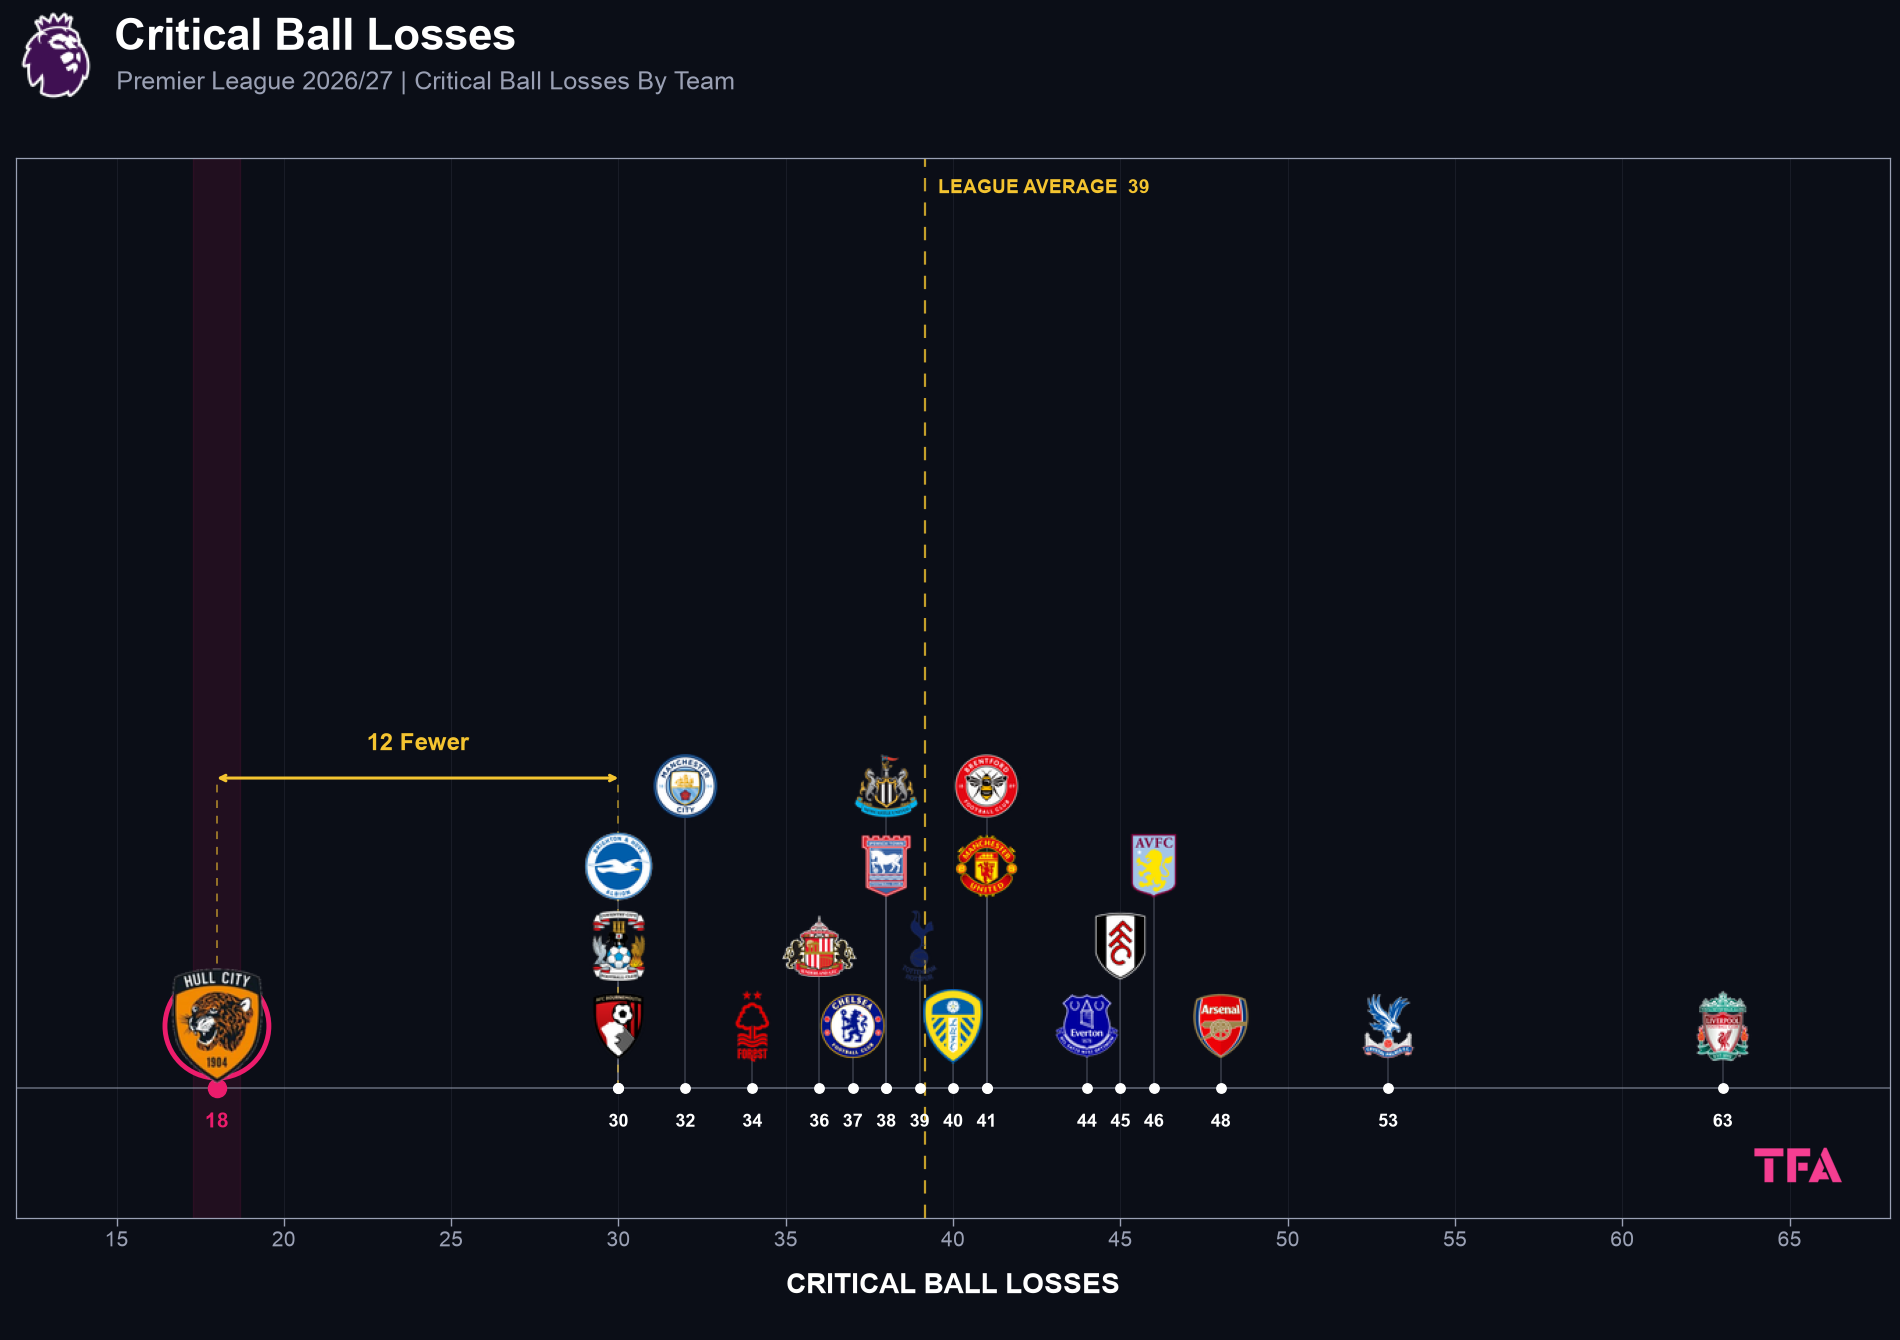

In [170]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

NAMES = {
    "Hull City": "Hull City",
    "AFC Bournemouth": "Bournemouth",
    "Coventry City": "Coventry City",
    "Brighton and Hove Albion": "Brighton",
    "Manchester City": "Manchester City",
    "Nottingham Forrest": "Nottingham Forest",
    "AFC Sunderland": "Sunderland",
    "Chelsea": "Chelsea",
    "Ipswich Town": "Ipswich Town",
    "Newcastle United": "Newcastle United",
    "Tottenham Hotspur": "Tottenham Hotspur",
    "Leeds United": "Leeds United",
    "Manchester United": "Manchester United",
    "Brentford": "Brentford",
    "Everton FC": "Everton",
    "Fulham": "Fulham",
    "Aston Villa": "Aston Villa",
    "Arsenal FC": "Arsenal",
    "Crystal Palace": "Crystal Palace",
    "Liverpool FC": "Liverpool",
}

LOSSES = [
    ("Hull City", 18), ("AFC Bournemouth", 30), ("Coventry City", 30), ("Brighton and Hove Albion", 30),
    ("Manchester City", 32), ("Nottingham Forrest", 34), ("AFC Sunderland", 36), ("Chelsea", 37),
    ("Ipswich Town", 38), ("Newcastle United", 38), ("Tottenham Hotspur", 39), ("Leeds United", 40),
    ("Manchester United", 41), ("Brentford", 41), ("Everton FC", 44), ("Fulham", 45),
    ("Aston Villa", 46), ("Arsenal FC", 48), ("Crystal Palace", 53), ("Liverpool FC", 63),
]

teams = [t for t, _ in LOSSES]
values = np.array([v for _, v in LOSSES], dtype=float)
avg_v = values.mean()

DPI = 100
W, H = 2048, 1536
LOGO_PX = 54
HULL_PX = 84

X_MIN, X_MAX = 12, 68
AX_RECT = [0.065, 0.085, 0.915, 0.69]
AX_W_PX = AX_RECT[2] * W
AX_H_PX = AX_RECT[3] * H
PX_PER_UNIT = AX_W_PX / (X_MAX - X_MIN)
BASE_Y = -400
STEP = 80
MIN_D = 74

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


placed = []
logo_y = {}
for raw, v in sorted(zip(teams, values), key=lambda p: p[1]):
    x_px = (v - X_MIN) * PX_PER_UNIT
    k = 0
    while True:
        y = BASE_Y + 62 + k * STEP
        if all(np.hypot(x_px - px, y - py) >= MIN_D for px, py in placed):
            break
        k += 1
    placed.append((x_px, y))
    logo_y[raw] = y

fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes(AX_RECT)
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(-AX_H_PX / 2, AX_H_PX / 2)
ax.set_xticks(range(15, 66, 5))
ax.set_yticks([])
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, axis="x", color="#9AA0B4", alpha=0.10, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("CRITICAL BALL LOSSES", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

ax.hlines(BASE_Y, X_MIN, X_MAX, color="#9AA0B4", alpha=0.5, linewidth=1.4, zorder=1)

ax.axvline(avg_v, color="#F4C430", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.8, zorder=1)
ax.text(avg_v + 0.4, AX_H_PX / 2 - 30, f"LEAGUE AVERAGE  {avg_v:.0f}", color="#F4C430", fontsize=14, fontweight="bold", va="center", ha="left")

hull_idx = teams.index("Hull City")
hull_v = values[hull_idx]

ax.axvspan(hull_v - 0.7, hull_v + 0.7, color="#EC1C6C", alpha=0.10, zorder=0)

for i, raw in enumerate(teams):
    is_hull = raw == "Hull City"
    v = values[i]
    ax.plot([v, v], [BASE_Y, logo_y[raw] - 30], color="#EC1C6C" if is_hull else "#9AA0B4", alpha=0.9 if is_hull else 0.3, linewidth=2 if is_hull else 1.2, zorder=2)
    ax.scatter([v], [BASE_Y], s=170 if is_hull else 46, color="#EC1C6C" if is_hull else "#FFFFFF", zorder=4)

for v in sorted(set(values)):
    is_hull = v == hull_v
    ax.text(v, BASE_Y - 34, f"{int(v)}", color="#EC1C6C" if is_hull else "#FFFFFF", fontsize=15 if is_hull else 13, fontweight="bold", va="center", ha="center", zorder=5)

for i, raw in enumerate(teams):
    display = NAMES[raw]
    is_hull = raw == "Hull City"
    path = find_logo(display)
    if path:
        img = load_resized(path, HULL_PX if is_hull else LOGO_PX)
        box = OffsetImage(img, zoom=1)
        ab = AnnotationBbox(box, (values[i], logo_y[raw]), frameon=False, box_alignment=(0.5, 0.5), zorder=6)
        ax.add_artist(ab)
    else:
        ax.text(values[i], logo_y[raw], display, color="#FFFFFF", fontsize=11, ha="center", va="center", zorder=6)

ax.scatter([hull_v], [logo_y["Hull City"]], s=5600, facecolor="none", edgecolor="#EC1C6C", linewidth=3.5, zorder=5)

gap_y = -90
ax.plot([hull_v, hull_v], [BASE_Y, gap_y], color="#F4C430", alpha=0.55, linewidth=1.4, linestyle=(0, (4, 4)), zorder=2)
ax.plot([30, 30], [BASE_Y, gap_y], color="#F4C430", alpha=0.55, linewidth=1.4, linestyle=(0, (4, 4)), zorder=2)
ax.annotate("", xy=(30, gap_y), xytext=(hull_v, gap_y), arrowprops=dict(arrowstyle="<->", color="#F4C430", linewidth=2.2, shrinkA=0, shrinkB=0), zorder=6)
ax.text((hull_v + 30) / 2, gap_y + 34, "12 Fewer", color="#F4C430", fontsize=17, fontweight="bold", va="center", ha="center", zorder=6)

ax.text(
    X_MIN + 0.5, 150,
    f" ",
    color="#EC1C6C", fontsize=16, fontweight="bold", va="center", ha="left", linespacing=1.5, zorder=6,
)

fig.text(0.211, 0.853, "Critical Ball Losses", color="#FFFFFF", fontsize=32, fontweight="bold", ha="center", va="center")
fig.text(0.265, 0.824, "Premier League 2026/27 | Critical Ball Losses By Team", color="#9AA0B4", fontsize=18, ha="center", va="center")

ax_tfa = fig.add_axes([0.907, 0.082, 0.075, 0.075])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.047, 0.812, 0.06, 0.06])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Premier League 2026-27 After 5 Matchweeks Goals Conceded Compared With xGA

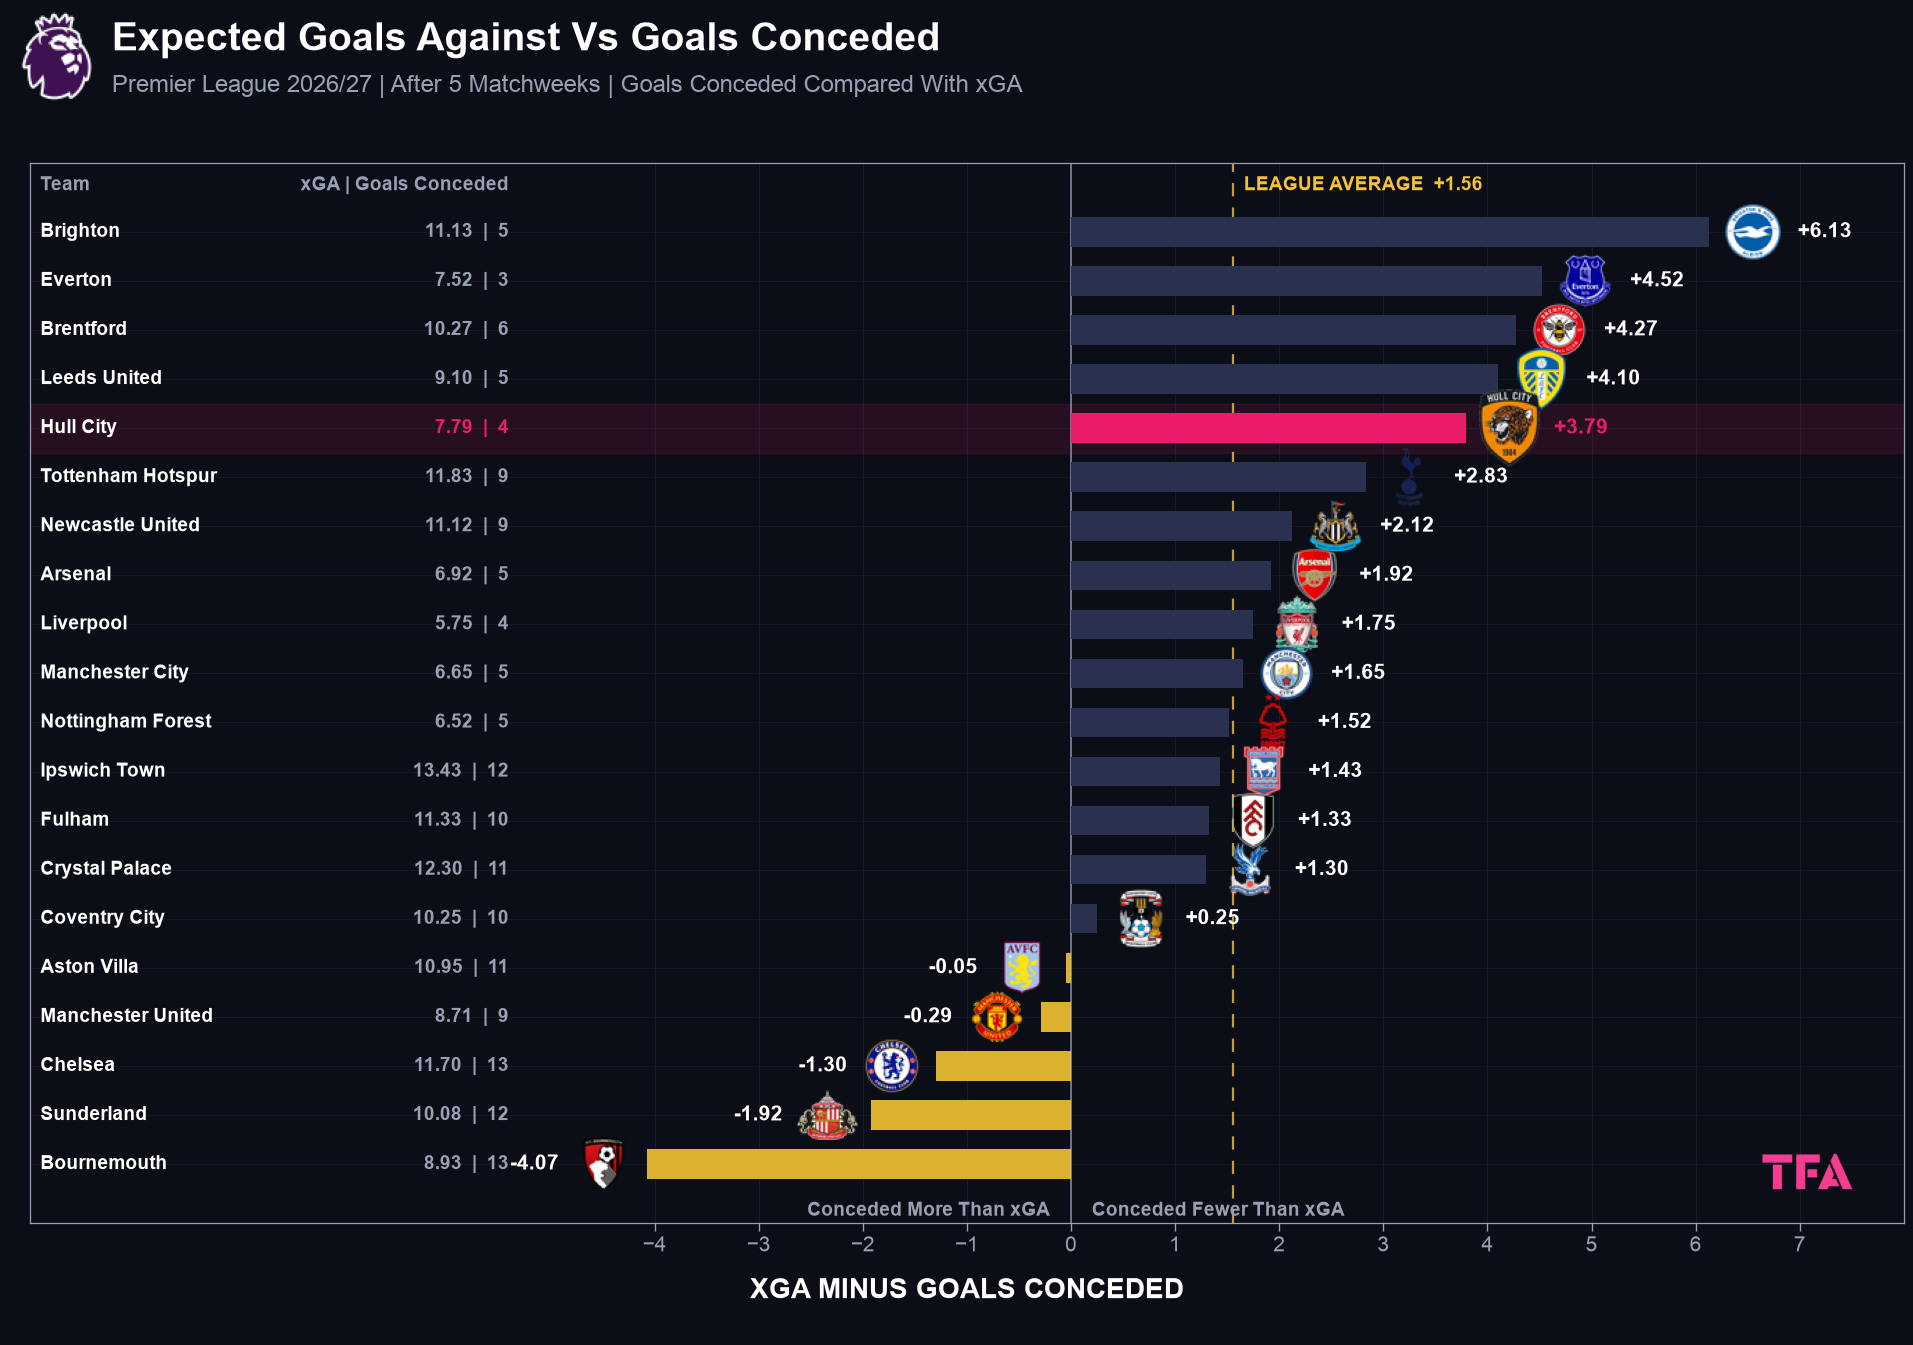

In [190]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

DATA = [
    ("Liverpool", 5.75, 4), ("Nottingham Forest", 6.52, 5), ("Manchester City", 6.65, 5),
    ("Arsenal", 6.92, 5), ("Everton", 7.52, 3), ("Hull City", 7.79, 4),
    ("Manchester United", 8.71, 9), ("Bournemouth", 8.93, 13), ("Leeds United", 9.10, 5),
    ("Sunderland", 10.08, 12), ("Coventry City", 10.25, 10), ("Brentford", 10.27, 6),
    ("Aston Villa", 10.95, 11), ("Newcastle United", 11.12, 9), ("Brighton", 11.13, 5),
    ("Fulham", 11.33, 10), ("Chelsea", 11.70, 13), ("Tottenham Hotspur", 11.83, 9),
    ("Crystal Palace", 12.30, 11), ("Ipswich Town", 13.43, 12),
]

AVG_XGA = 9.61
AVG_GC = 8.05
avg_diff = AVG_XGA - AVG_GC

rows = sorted([(t, x, g, x - g) for t, x, g in DATA], key=lambda r: -r[3])
ypos = np.arange(len(rows))
hull_idx = [r[0] for r in rows].index("Hull City")

DPI = 100
W, H = 2048, 1536
LOGO_PX = 44
HULL_PX = 56

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes([0.065, 0.085, 0.915, 0.69])
ax.set_xlim(-10, 8)
ax.set_ylim(20.2, -1.4)
ax.set_xticks(range(-4, 8, 1))
ax.set_yticks([])
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, axis="x", color="#9AA0B4", alpha=0.10, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("XGA MINUS GOALS CONCEDED", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

ax.axhspan(hull_idx - 0.5, hull_idx + 0.5, color="#EC1C6C", alpha=0.12, zorder=0)
ax.hlines(ypos, -10, 8, color="#9AA0B4", alpha=0.07, linewidth=0.8, zorder=1)
ax.axvline(0, color="#9AA0B4", alpha=0.7, linewidth=1.4, zorder=2)

ax.axvline(avg_diff, color="#F4C430", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.8, zorder=2)
ax.text(avg_diff + 0.1, -0.95, f"LEAGUE AVERAGE  {avg_diff:+.2f}", color="#F4C430", fontsize=14, fontweight="bold", va="center", ha="left")

ax.text(-9.9, -0.95, "Team", color="#9AA0B4", fontsize=14, fontweight="bold", va="center", ha="left")
ax.text(-5.4, -0.95, "xGA | Goals Conceded", color="#9AA0B4", fontsize=14, fontweight="bold", va="center", ha="right")
ax.text(-0.2, 19.95, "Conceded More Than xGA", color="#9AA0B4", fontsize=14, fontweight="bold", va="center", ha="right")
ax.text(0.2, 19.95, "Conceded Fewer Than xGA", color="#9AA0B4", fontsize=14, fontweight="bold", va="center", ha="left")

for i, (team, xga, gc, diff) in enumerate(rows):
    is_hull = team == "Hull City"
    if is_hull:
        bar_color = "#EC1C6C"
    elif diff >= 0:
        bar_color = "#2A3150"
    else:
        bar_color = "#F4C430"
    ax.barh(i, diff, height=0.6, color=bar_color, alpha=0.9 if bar_color == "#F4C430" else 1.0, zorder=3)

    ax.text(-9.9, i, team, color="#FFFFFF", fontsize=14, fontweight="bold", va="center", ha="left", zorder=5)
    ax.text(-5.4, i, f"{xga:.2f}  |  {gc}", color="#EC1C6C" if is_hull else "#9AA0B4", fontsize=14, fontweight="bold", va="center", ha="right", zorder=5)

    side = 1 if diff >= 0 else -1
    path = find_logo(team)
    if path:
        img = load_resized(path, HULL_PX if is_hull else LOGO_PX)
        box = OffsetImage(img, zoom=1)
        ab = AnnotationBbox(box, (diff + side * 0.42, i), frameon=False, box_alignment=(0.5, 0.5), zorder=6)
        ax.add_artist(ab)
    ax.text(diff + side * 0.85, i, f"{diff:+.2f}", color="#EC1C6C" if is_hull else "#FFFFFF", fontsize=15, fontweight="bold", va="center", ha="left" if side == 1 else "right", zorder=6)

hull = rows[hull_idx]
ax.text(
    3.0, 15.2,
    f" ",
    color="#EC1C6C", fontsize=16, fontweight="bold", va="center", ha="left", linespacing=1.5, zorder=6,
)

fig.text(0.105, 0.855, "Expected Goals Against Vs Goals Conceded", color="#FFFFFF", fontsize=28, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League 2026/27 | After 5 Matchweeks | Goals Conceded Compared With xGA", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.904, 0.08, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Premier League 2026/2027 Open Play Expected Goals Vs Total Expected Goals

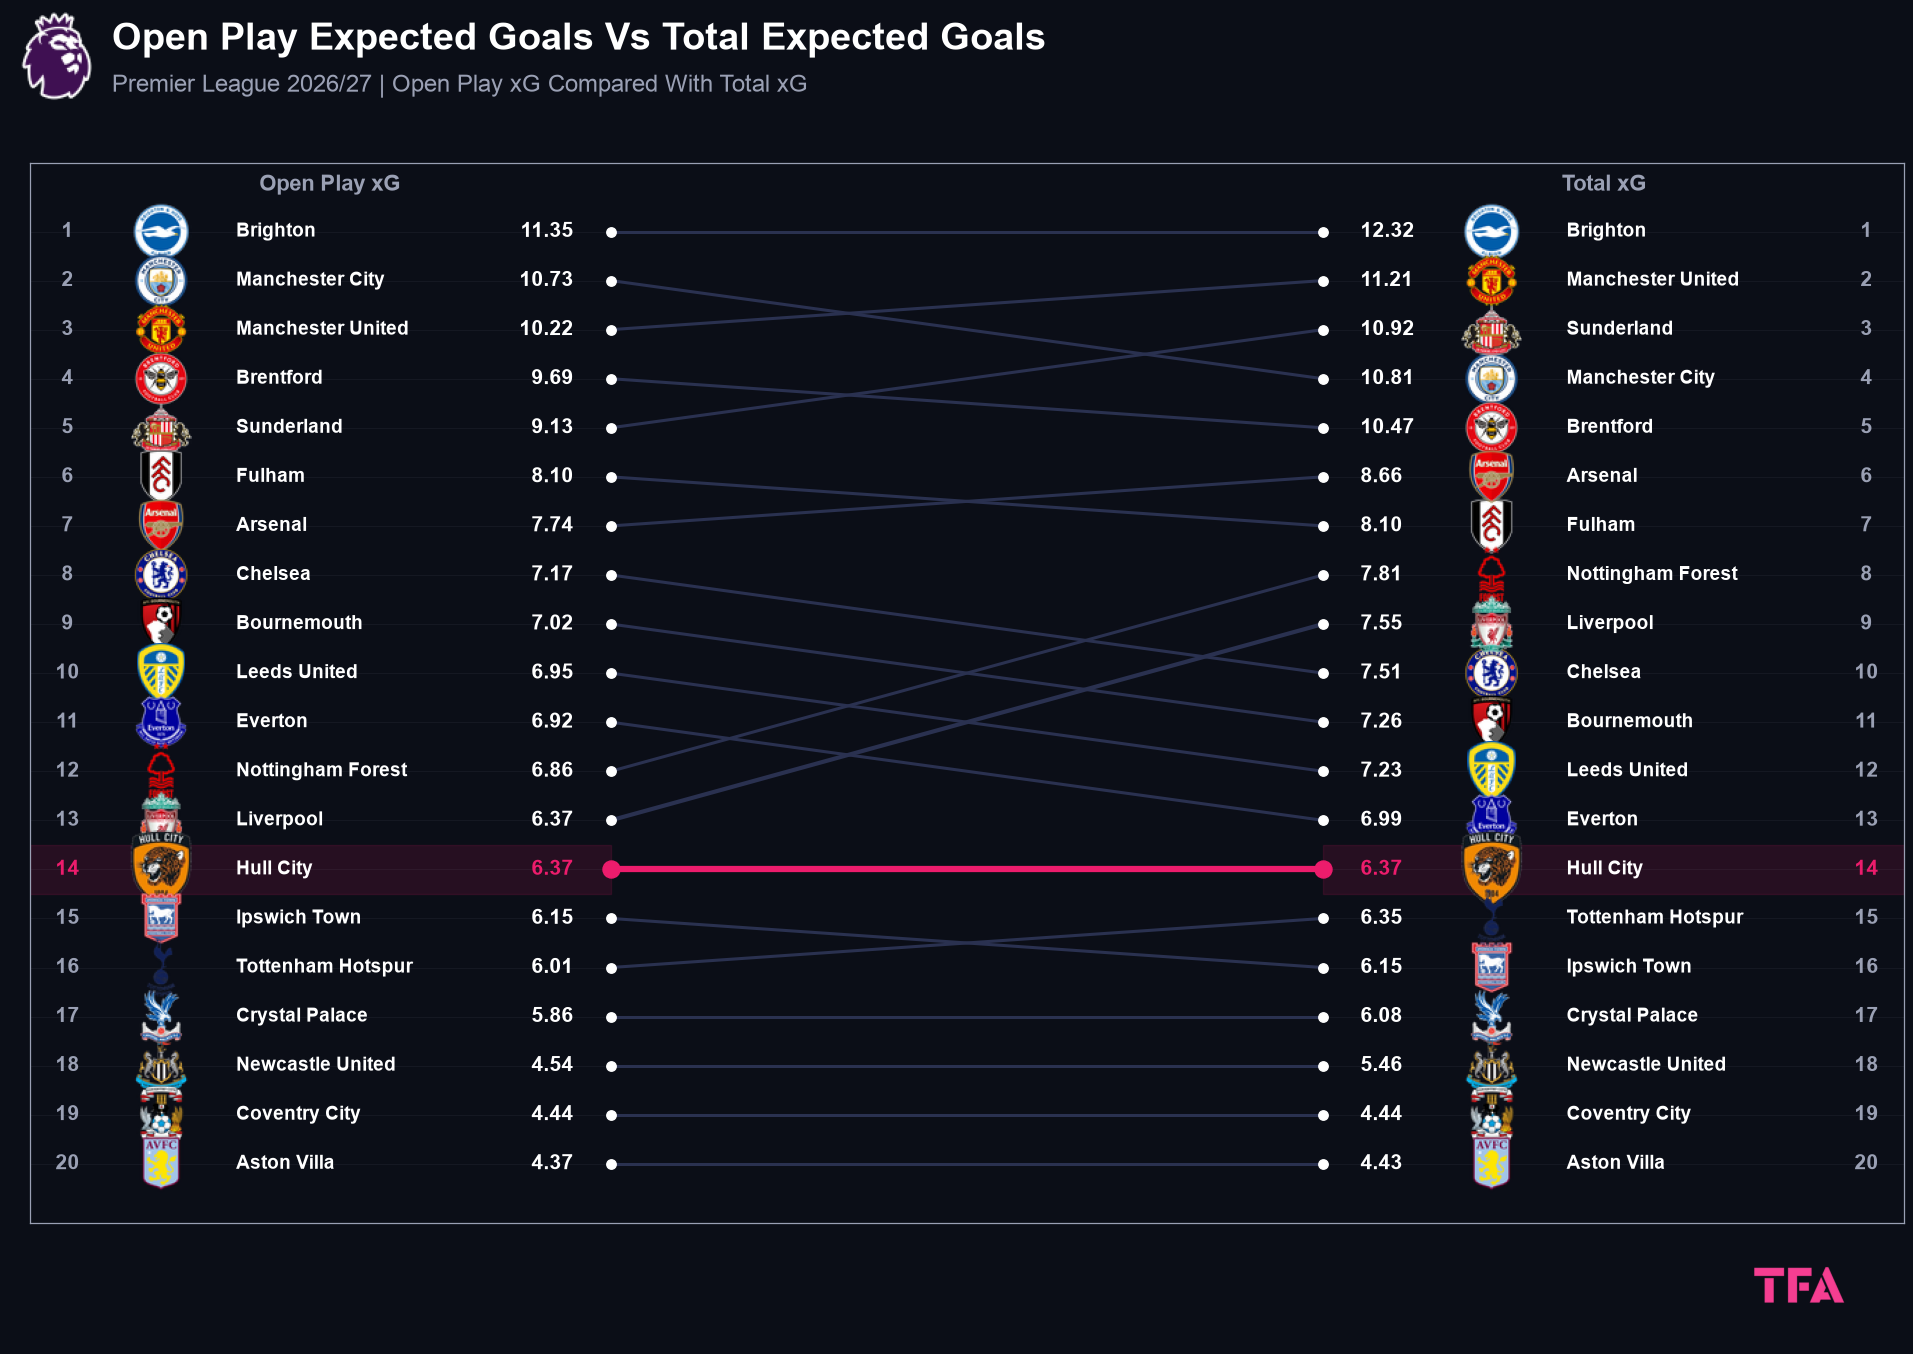

In [201]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

NAMES = {
    "Brighton and Hove Albion": "Brighton",
    "Manchester City": "Manchester City",
    "Manchester United": "Manchester United",
    "Brentford": "Brentford",
    "AFC Sunderland": "Sunderland",
    "Fulham": "Fulham",
    "Arsenal FC": "Arsenal",
    "Chelsea": "Chelsea",
    "AFC Bournemouth": "Bournemouth",
    "Leeds United": "Leeds United",
    "Everton FC": "Everton",
    "Nottingham Forrest": "Nottingham Forest",
    "Liverpool FC": "Liverpool",
    "Hull City": "Hull City",
    "Ipswich Town": "Ipswich Town",
    "Tottenham Hotspur": "Tottenham Hotspur",
    "Crystal Palace": "Crystal Palace",
    "Newcastle United": "Newcastle United",
    "Coventry City": "Coventry City",
    "Aston Villa": "Aston Villa",
}

OPEN_PLAY = [
    ("Brighton and Hove Albion", 11.35), ("Manchester City", 10.73), ("Manchester United", 10.22),
    ("Brentford", 9.69), ("AFC Sunderland", 9.13), ("Fulham", 8.10), ("Arsenal FC", 7.74),
    ("Chelsea", 7.17), ("AFC Bournemouth", 7.02), ("Leeds United", 6.95), ("Everton FC", 6.92),
    ("Nottingham Forrest", 6.86), ("Liverpool FC", 6.37), ("Hull City", 6.37), ("Ipswich Town", 6.15),
    ("Tottenham Hotspur", 6.01), ("Crystal Palace", 5.86), ("Newcastle United", 4.54),
    ("Coventry City", 4.44), ("Aston Villa", 4.37),
]

TOTAL = [
    ("Brighton and Hove Albion", 12.32), ("Manchester United", 11.21), ("AFC Sunderland", 10.92),
    ("Manchester City", 10.81), ("Brentford", 10.47), ("Arsenal FC", 8.66), ("Fulham", 8.10),
    ("Nottingham Forrest", 7.81), ("Liverpool FC", 7.55), ("Chelsea", 7.51), ("AFC Bournemouth", 7.26),
    ("Leeds United", 7.23), ("Everton FC", 6.99), ("Hull City", 6.37), ("Tottenham Hotspur", 6.35),
    ("Ipswich Town", 6.15), ("Crystal Palace", 6.08), ("Newcastle United", 5.46),
    ("Coventry City", 4.44), ("Aston Villa", 4.43),
]

left_rank = {t: i for i, (t, _) in enumerate(OPEN_PLAY)}
right_rank = {t: i for i, (t, _) in enumerate(TOTAL)}
left_val = dict(OPEN_PLAY)
right_val = dict(TOTAL)

DPI = 100
W, H = 2048, 1536
LOGO_PX = 44
HULL_PX = 56

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


def put_logo(ax, display, x, y, size):
    path = find_logo(display)
    if path:
        box = OffsetImage(load_resized(path, size), zoom=1)
        ab = AnnotationBbox(box, (x, y), frameon=False, box_alignment=(0.5, 0.5), zorder=6)
        ax.add_artist(ab)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes([0.065, 0.085, 0.915, 0.69])
ax.set_xlim(0, 100)
ax.set_ylim(20.2, -1.4)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)

ax.hlines(np.arange(20), 0, 31, color="#9AA0B4", alpha=0.07, linewidth=0.8, zorder=1)
ax.hlines(np.arange(20), 69, 100, color="#9AA0B4", alpha=0.07, linewidth=0.8, zorder=1)

ax.text(16, -0.95, "Open Play xG", color="#9AA0B4", fontsize=16, fontweight="bold", va="center", ha="center")
ax.text(84, -0.95, "Total xG", color="#9AA0B4", fontsize=16, fontweight="bold", va="center", ha="center")

for raw, _ in OPEN_PLAY:
    display = NAMES[raw]
    yl = left_rank[raw]
    yr = right_rank[raw]
    is_hull = raw == "Hull City"
    is_liv = raw == "Liverpool FC"

    if is_hull:
        line_color = "#EC1C6C"
        lw = 4.5
        z = 4
    elif is_liv:
        line_color = "#2A3150"
        lw = 3
        z = 3
    else:
        line_color = "#2A3150"
        lw = 2.2
        z = 2

    if is_hull:
        ax.fill_between([0, 31], yl - 0.5, yl + 0.5, color="#EC1C6C", alpha=0.12, zorder=0)
        ax.fill_between([69, 100], yr - 0.5, yr + 0.5, color="#EC1C6C", alpha=0.12, zorder=0)

    ax.plot([31, 69], [yl, yr], color=line_color, linewidth=lw, solid_capstyle="round", zorder=z)
    ax.scatter([31, 69], [yl, yr], s=150 if is_hull else 46, color="#EC1C6C" if is_hull else ("#FFFFFF" if is_liv else "#FFFFFF"), zorder=z + 1)

    ax.text(2, yl, f"{yl + 1}", color="#EC1C6C" if is_hull else "#9AA0B4", fontsize=15, fontweight="bold", va="center", ha="center", zorder=5)
    put_logo(ax, display, 7, yl, HULL_PX if is_hull else LOGO_PX)
    ax.text(11, yl, display, color="#FFFFFF", fontsize=14, fontweight="bold", va="center", ha="left", zorder=5)
    ax.text(29, yl, f"{left_val[raw]:.2f}", color="#EC1C6C" if is_hull else "#FFFFFF", fontsize=15, fontweight="bold", va="center", ha="right", zorder=5)

    ax.text(71, yr, f"{right_val[raw]:.2f}", color="#EC1C6C" if is_hull else "#FFFFFF", fontsize=15, fontweight="bold", va="center", ha="left", zorder=5)
    put_logo(ax, display, 78, yr, HULL_PX if is_hull else LOGO_PX)
    ax.text(82, yr, display, color="#FFFFFF", fontsize=14, fontweight="bold", va="center", ha="left", zorder=5)
    ax.text(98, yr, f"{yr + 1}", color="#EC1C6C" if is_hull else "#9AA0B4", fontsize=15, fontweight="bold", va="center", ha="center", zorder=5)

fig.text(0.105, 0.855, "Open Play Expected Goals Vs Total Expected Goals", color="#FFFFFF", fontsize=27, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League 2026/27 | Open Play xG Compared With Total xG", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.9, 0.006, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

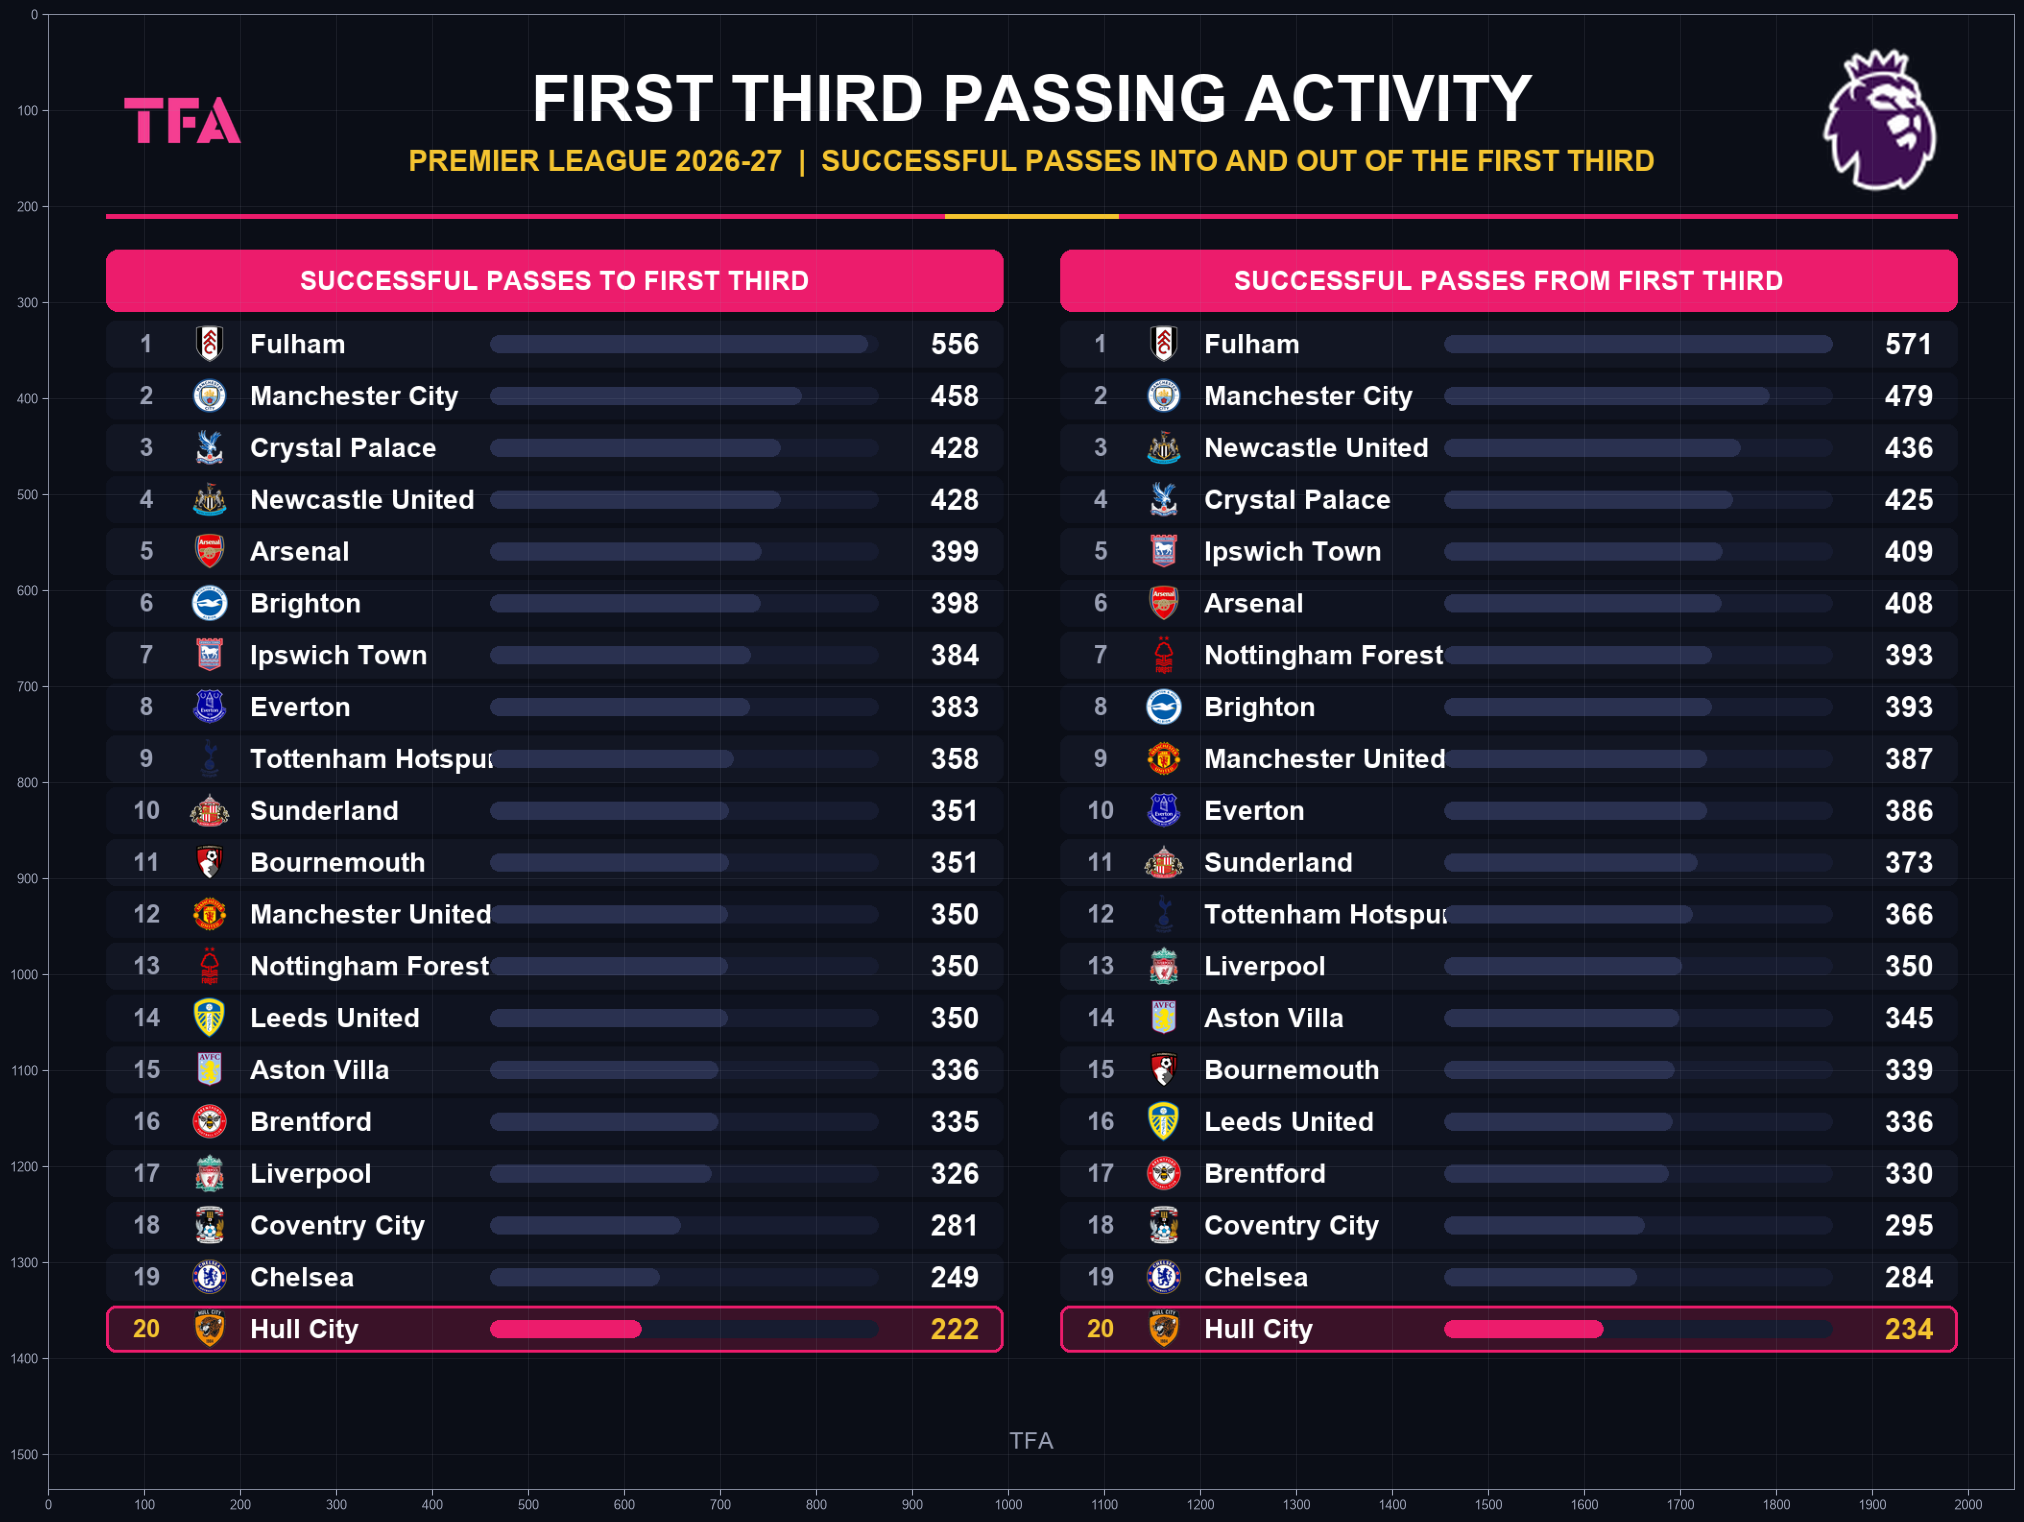

In [97]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

W, H = 2048, 1536
BG = "#0B0E17"
PINK = "#EC1C6C"
GOLD = "#F4C430"
WHITE = "#FFFFFF"
GREY = "#9AA0B4"
ROW_A = "#121623"
ROW_B = "#0F1320"
BAR = "#2A3150"
HULL_ROW = "#3A1228"

NAMES = {
    "Fulham": "Fulham",
    "Manchester City": "Manchester City",
    "Crystal Palace": "Crystal Palace",
    "Newcastle United": "Newcastle United",
    "Arsenal FC": "Arsenal",
    "Brighton and Hove Albion": "Brighton",
    "Ipswich Town": "Ipswich Town",
    "Everton FC": "Everton",
    "Tottenham Hotspur": "Tottenham Hotspur",
    "AFC Sunderland": "Sunderland",
    "AFC Bournemouth": "Bournemouth",
    "Manchester United": "Manchester United",
    "Nottingham Forrest": "Nottingham Forest",
    "Leeds United": "Leeds United",
    "Aston Villa": "Aston Villa",
    "Brentford": "Brentford",
    "Liverpool FC": "Liverpool",
    "Coventry City": "Coventry City",
    "Chelsea": "Chelsea",
    "Hull City": "Hull City",
}

INTO = [
    (1, "Fulham", 556), (2, "Manchester City", 458), (3, "Crystal Palace", 428),
    (4, "Newcastle United", 428), (5, "Arsenal FC", 399), (6, "Brighton and Hove Albion", 398),
    (7, "Ipswich Town", 384), (8, "Everton FC", 383), (9, "Tottenham Hotspur", 358),
    (10, "AFC Sunderland", 351), (11, "AFC Bournemouth", 351), (12, "Manchester United", 350),
    (13, "Nottingham Forrest", 350), (14, "Leeds United", 350), (15, "Aston Villa", 336),
    (16, "Brentford", 335), (17, "Liverpool FC", 326), (18, "Coventry City", 281),
    (19, "Chelsea", 249), (20, "Hull City", 222),
]

FROM = [
    (1, "Fulham", 571), (2, "Manchester City", 479), (3, "Newcastle United", 436),
    (4, "Crystal Palace", 425), (5, "Ipswich Town", 409), (6, "Arsenal FC", 408),
    (7, "Nottingham Forrest", 393), (8, "Brighton and Hove Albion", 393), (9, "Manchester United", 387),
    (10, "Everton FC", 386), (11, "AFC Sunderland", 373), (12, "Tottenham Hotspur", 366),
    (13, "Liverpool FC", 350), (14, "Aston Villa", 345), (15, "AFC Bournemouth", 339),
    (16, "Leeds United", 336), (17, "Brentford", 330), (18, "Coventry City", 295),
    (19, "Chelsea", 284), (20, "Hull City", 234),
]

FONT_BOLD_CANDIDATES = [
    "/System/Library/Fonts/Supplemental/Arial Bold.ttf",
    "/Library/Fonts/Arial Bold.ttf",
    "/System/Library/Fonts/Helvetica.ttc",
    "DejaVuSans-Bold.ttf",
]
FONT_REG_CANDIDATES = [
    "/System/Library/Fonts/Supplemental/Arial.ttf",
    "/Library/Fonts/Arial.ttf",
    "/System/Library/Fonts/Helvetica.ttc",
    "DejaVuSans.ttf",
]


def load_font(candidates, size):
    for path in candidates:
        try:
            return ImageFont.truetype(path, size)
        except OSError:
            continue
    return ImageFont.load_default()


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def fit_image(path, box_w, box_h):
    img = Image.open(path).convert("RGBA")
    ratio = min(box_w / img.width, box_h / img.height)
    new_size = (max(1, int(img.width * ratio)), max(1, int(img.height * ratio)))
    return img.resize(new_size, Image.LANCZOS)


def paste_centered(canvas, img, cx, cy):
    x = int(cx - img.width / 2)
    y = int(cy - img.height / 2)
    canvas.paste(img, (x, y), img)


canvas = Image.new("RGB", (W, H), BG)
draw = ImageDraw.Draw(canvas)

f_title = load_font(FONT_BOLD_CANDIDATES, 66)
f_sub = load_font(FONT_BOLD_CANDIDATES, 30)
f_head = load_font(FONT_BOLD_CANDIDATES, 27)
f_rank = load_font(FONT_BOLD_CANDIDATES, 26)
f_team = load_font(FONT_BOLD_CANDIDATES, 28)
f_val = load_font(FONT_BOLD_CANDIDATES, 30)
f_foot = load_font(FONT_REG_CANDIDATES, 24)

tfa = fit_image(TFA_LOGO, 230, 160)
epl = fit_image(EPL_LOGO, 230, 160)
paste_centered(canvas, tfa, 60 + tfa.width / 2, 110)
paste_centered(canvas, epl, W - 60 - epl.width / 2, 110)

draw.text((W / 2, 88), "FIRST THIRD PASSING ACTIVITY", font=f_title, fill=WHITE, anchor="mm")
draw.text((W / 2, 152), "PREMIER LEAGUE 2026-27  |  SUCCESSFUL PASSES INTO AND OUT OF THE FIRST THIRD", font=f_sub, fill=GOLD, anchor="mm")

draw.rectangle([60, 208, W - 60, 212], fill=PINK)
draw.rectangle([W // 2 - 90, 208, W // 2 + 90, 212], fill=GOLD)

MARGIN = 60
GAP = 60
TABLE_W = (W - 2 * MARGIN - GAP) // 2
HEAD_Y = 245
HEAD_H = 64
ROW_H = 54
ROWS_Y = HEAD_Y + HEAD_H + 10
GLOBAL_MAX = max(max(v for _, _, v in INTO), max(v for _, _, v in FROM))

logo_cache = {}


def team_logo(raw_name):
    display = NAMES[raw_name]
    if display not in logo_cache:
        path = find_logo(display)
        logo_cache[display] = fit_image(path, 42, 42) if path else None
    return logo_cache[display]


def draw_table(x0, title, data):
    draw.rounded_rectangle([x0, HEAD_Y, x0 + TABLE_W, HEAD_Y + HEAD_H], radius=12, fill=PINK)
    draw.text((x0 + TABLE_W / 2, HEAD_Y + HEAD_H / 2), title, font=f_head, fill=WHITE, anchor="mm")

    bar_x0 = x0 + 400
    bar_x1 = x0 + TABLE_W - 130
    bar_w = bar_x1 - bar_x0

    for i, (rank, raw_name, value) in enumerate(data):
        y = ROWS_Y + i * ROW_H
        is_hull = raw_name == "Hull City"
        fill = HULL_ROW if is_hull else (ROW_A if i % 2 == 0 else ROW_B)
        draw.rounded_rectangle([x0, y, x0 + TABLE_W, y + ROW_H - 6], radius=10, fill=fill,
                               outline=PINK if is_hull else None, width=3 if is_hull else 0)
        cy = y + (ROW_H - 6) / 2

        draw.text((x0 + 42, cy), str(rank), font=f_rank, fill=GOLD if is_hull else GREY, anchor="mm")

        logo = team_logo(raw_name)
        if logo:
            paste_centered(canvas, logo, x0 + 108, cy)

        draw.text((x0 + 150, cy), NAMES[raw_name], font=f_team, fill=WHITE, anchor="lm")

        draw.rounded_rectangle([bar_x0, cy - 9, bar_x1, cy + 9], radius=9, fill="#171C30")
        fill_w = max(12, int(bar_w * value / GLOBAL_MAX))
        draw.rounded_rectangle([bar_x0, cy - 9, bar_x0 + fill_w, cy + 9], radius=9, fill=PINK if is_hull else BAR)

        draw.text((x0 + TABLE_W - 24, cy), str(value), font=f_val, fill=GOLD if is_hull else WHITE, anchor="rm")


draw_table(MARGIN, "SUCCESSFUL PASSES TO FIRST THIRD", INTO)
draw_table(MARGIN + TABLE_W + GAP, "SUCCESSFUL PASSES FROM FIRST THIRD", FROM)

draw.text((W / 2, H - 50), "TFA", font=f_foot, fill=GREY, anchor="mm")

fig = plt.figure(figsize=(W / 100, H / 100), dpi=100, facecolor=BG)
ax = fig.add_axes([0.035, 0.035, 0.96, 0.96])
ax.imshow(canvas, extent=[0, W, H, 0], aspect="auto")
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.set_xticks(range(0, W + 1, 100))
ax.set_yticks(range(0, H + 1, 100))
ax.tick_params(colors=GREY, labelsize=9, length=4)
for spine in ax.spines.values():
    spine.set_color(GREY)
    spine.set_linewidth(0.6)
ax.set_facecolor(BG)
ax.grid(True, color=GREY, alpha=0.15, linewidth=0.5)
plt.show()